# Market data anomaly detector

A wrong price propagates into the P&L, the VaR and every model fitted on it; catching it at ingestion is cheaper than explaining a false loss. Market data has no labels of what is wrong, so the detector is measured on errors injected into the real closes of the fourteen Yahoo price series (the CAC 40, Euro Stoxx 50, S&P 500, gold and the ten stocks), with a fixed seed: 200 errors of each type at random dates and series, at least seven sessions apart on a series ([`pipeline/anomaly_evaluation.py`](../pipeline/anomaly_evaluation.py); gold tables `fact_anomaly_evaluation` and `fact_anomaly_top_moves`).

| Error | Injected as |
|---|---|
| Spike | one close moved by 5% to 20%, back to normal the next day |
| Frozen price | the previous close repeated for 3 to 5 sessions |
| Decimal shift | one close multiplied by 10 or divided by 10 |
| Unadjusted split | every close from a date divided by 2 |
| Missing days | 1 to 3 sessions removed |
| Roll jump | every close from a date moved by 2% to 6%, as when a futures series rolls |

**Layers.** *Rules*: the quality gate's stale-value and missing-session checks. *Robust z-score* ([`pipeline/anomalies.py`](../pipeline/anomalies.py)): the return's distance from the median of the previous 63 returns in units of 1.4826 × MAD (Rousseeuw and Croux, 1993; Iglewicz and Hoaglin, 1993), flagged as a *bad tick* above 6 when at least two thirds of the move reverses the next day and the median robust z of the other series stays within ±3, and as a *level shift* above 30, beyond any real move since 2008. *Isolation Forest* (Liu, Ting and Zhou, 2008) on the return, the next return, the return over the 63-day volatility and the other series' median return, fitted on the real data with two alarm budgets. A flag counts as correct when it falls on a wrong day or the session after it.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "requirements.txt").exists())
GOLD = ROOT / "data" / "gold"
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e6e5e1", "#fcfcfb"
plt.rcParams.update(
    {
        "figure.figsize": (9, 3.6),
        "figure.dpi": 110,
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "axes.edgecolor": GRID,
        "axes.labelcolor": INK2,
        "axes.titlecolor": INK,
        "axes.titlesize": 11,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": GRID,
        "grid.linewidth": 0.6,
        "xtick.color": INK2,
        "ytick.color": INK2,
        "lines.linewidth": 1.5,
        "legend.frameon": False,
        "font.size": 9,
    }
)
ERROR_TYPES = {
    "spike": "Spike",
    "frozen": "Frozen price",
    "decimal_shift": "Decimal shift",
    "split": "Unadjusted split",
    "missing_days": "Missing days",
    "roll_jump": "Roll jump",
}

evaluation = pd.read_parquet(GOLD / "fact_anomaly_evaluation.parquet").sort_values("layer_order")
top_moves = pd.read_parquet(GOLD / "fact_anomaly_top_moves.parquet")
flags = pd.read_parquet(GOLD / "fact_dq_flags.parquet").assign(date=lambda d: pd.to_datetime(d["date"]))
names = pd.read_parquet(GOLD / "dim_instrument.parquet").set_index("instrument_id")["short_name"]
print(f"{int(evaluation['n_per_type'].iloc[0])} errors of each type, seed {int(evaluation['seed'].iloc[0])}")

200 errors of each type, seed 2


## 1. Recall and precision by layer

In [2]:
table = evaluation.set_index("layer")[["n_flags", "precision", *(f"recall_{kind}" for kind in ERROR_TYPES)]]
table.columns = ["flags", "precision", *ERROR_TYPES.values()]
table.round(3)

,flags,precision,Spike,Frozen price,Decimal shift,Unadjusted split,Missing days,Roll jump
layer,,,,,,,,
"Rules: stale, missing sessions",1164,0.860,0.000,1.000,0.00,0.000,1.000,0.000
Robust z-score,761,0.992,0.785,0.005,1.00,0.955,0.005,0.000
"Isolation Forest, 0.1% budget",340,0.859,0.435,0.005,0.99,0.005,0.000,0.000
"Isolation Forest, 1% budget",1411,0.632,0.865,0.035,1.00,0.850,0.025,0.105
Production: rules + z-score,1925,0.912,0.785,1.000,1.00,0.955,1.000,0.000


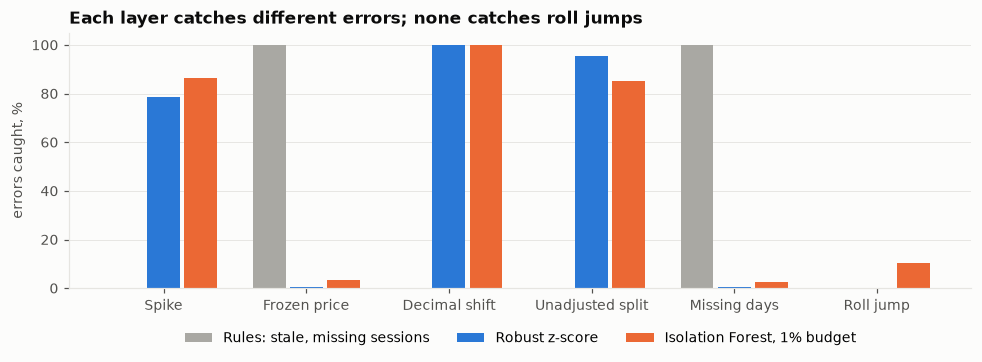

In [3]:
shown = {
    "Rules: stale, missing sessions": "#a9a8a3",
    "Robust z-score": "#2a78d6",
    "Isolation Forest, 1% budget": "#eb6834",
}
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.set_axisbelow(True)
width = 0.26
for offset, (layer, color) in enumerate(shown.items()):
    values = (
        evaluation.set_index("layer")
        .loc[layer, [f"recall_{kind}" for kind in ERROR_TYPES]]
        .to_numpy(dtype=float)
    )
    ax.bar(
        np.arange(len(ERROR_TYPES)) + (offset - 1) * width,
        values * 100,
        width=width - 0.03,
        color=color,
        label=layer,
    )
ax.set_xticks(range(len(ERROR_TYPES)), list(ERROR_TYPES.values()))
ax.set_ylabel("errors caught, %")
ax.set_ylim(0, 105)
ax.set_title("Each layer catches different errors; none catches roll jumps")
ax.legend(loc="upper center", ncol=3, bbox_to_anchor=(0.5, -0.12))
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

The layers are complementary. The rules catch every frozen price and every missing day; their precision of 0.860 comes from real gaps and repeated values already in the data, not from mistakes. The robust z-score catches every decimal shift, 95.5% of the splits and 78.5% of the spikes, with a precision of 0.992. The spikes it misses are those that stay inside the series' normal range at the time (a robust z below 6); the splits it misses fall in volatile years, where halving the price scores just under 30. Together, rules and z-score (the production detector) catch every frozen price, missing day and decimal shift with a precision of 0.912.

The Isolation Forest does not earn its place. At 0.1% of real days flagged it catches decimal shifts (99%) but only 43.5% of spikes and almost no splits; at 1% it catches more spikes (86.5%) and splits (85%) but its precision falls to 0.632. On these data, explicit checks of the two signatures of a data error (a move that comes back, a move no other asset shares) beat a general-purpose outlier score, consistent with benchmarks where no unsupervised detector dominates (Han et al., 2022). No layer catches roll jumps of 2% to 6%, which look like ordinary moves: they need the futures roll calendar or a second source.

## 2. False alarm check: the largest real moves

In [4]:
view = top_moves.assign(
    series=top_moves["instrument_id"].map(names),
    date=pd.to_datetime(top_moves["date"]).dt.date,
    production_detector=top_moves["flagged_by"].str.contains("Production"),
    forest_at_0_1_percent=top_moves["flagged_by"].str.contains("Forest, 0.1% budget", regex=False),
    forest_at_1_percent=top_moves["flagged_by"].str.contains("Forest, 1% budget", regex=False),
)
view[
    [
        "date",
        "series",
        "log_return",
        "robust_z",
        "production_detector",
        "forest_at_0_1_percent",
        "forest_at_1_percent",
    ]
].round(3)

,date,series,log_return,robust_z,production_detector,forest_at_0_1_percent,forest_at_1_percent
0,2020-03-18,Airbus,-0.251,-15.006,False,True,True
1,2023-10-27,Sanofi,-0.210,-18.841,False,False,True
2,2009-02-20,AXA,-0.204,-3.984,False,False,True
3,2008-09-19,AXA,0.193,5.634,False,True,True
4,2016-06-24,BNP Paribas,-0.191,-11.371,False,True,True
5,2008-12-17,BNP Paribas,-0.189,-3.787,False,False,True
6,2009-01-28,BNP Paribas,0.189,4.362,False,False,True
7,2009-03-10,BNP Paribas,0.188,4.304,False,False,True
8,2020-03-12,Vinci,-0.187,-17.297,False,True,True
9,2020-03-26,Airbus,0.186,8.932,False,False,True


The production detector flags none of the ten largest real moves, including Sanofi's 19% fall on 27 October 2023 (a log return of −0.210), a robust z of −18.8 on a day when the other series were quiet: it did not reverse, and it stays below the level-shift threshold of 30. The Isolation Forest flags four of them at 0.1% of days and all ten at 1%: extreme but genuine days are exactly what a generic outlier score isolates.

## 3. What the detector flags in the real data

In [5]:
latest = flags[flags["is_latest_run"] & (flags["rule"] == "suspect_tick")].sort_values("date")
volumes = pd.read_parquet(GOLD / "fact_volume_forecast.parquet").assign(
    date=lambda d: pd.to_datetime(d["date"])
)
volumes = volumes[volumes["model_id"] == "adv20"].set_index(["date", "instrument_id"])["actual_vs_adv"]
latest = latest.assign(
    series=latest["instrument"].map(names),
    third_friday=(latest["date"].dt.dayofweek == 4) & ((latest["date"].dt.day - 1) // 7 == 2),
    volume_vs_adv=[
        volumes.get((day, instrument), np.nan)
        for day, instrument in zip(latest["date"], latest["instrument"], strict=True)
    ],
)
latest.assign(date=latest["date"].dt.date)[
    ["date", "series", "detail", "third_friday", "volume_vs_adv"]
].round(1)

,date,series,detail,third_friday,volume_vs_adv
1988,2011-08-08,S&P 500,"bad tick: robust z -7.6, reverted the next day",False,NaN
1989,2020-03-04,S&P 500,"bad tick: robust z +6.4, reverted the next day",False,NaN
1990,2020-03-10,S&P 500,"bad tick: robust z +7.0, reverted the next day",False,NaN
1992,2020-03-20,Airbus,"bad tick: robust z +9.7, reverted the next day",True,1.5
1991,2023-06-16,Air Liquide,"bad tick: robust z +7.7, reverted the next day",True,5.6


On the real history the detector raises five warnings since 2008. Three are sharp reversals of the S&P 500 in crises (8 August 2011, 4 and 10 March 2020) and one an Airbus round trip on 20 March 2020: genuine moves that reversed within a day, the price of a reversal check. The fifth, Air Liquide on 16 June 2023, is a quarterly expiry Friday with volume 5.6 times the 20-day ADV, and the price fell back the next session: most likely a close shaped by the expiry auction, real but not representative of the stock's value, which is the kind of price a desk would want reviewed before it enters a valuation.

## 4. Conclusions and consequences

| Finding | Consequence |
|---|---|
| Rules and the robust z-score together catch every frozen price, missing day and decimal shift, 95.5% of splits and 78.5% of spikes, with a precision of 0.912 | The quality gate runs both; suspect prices are a warning rule (`suspect_tick`) on the Data quality page |
| The production detector flags none of the ten largest real moves and five days in eighteen years of real data | The alarm rate is low enough for a person to review every flag |
| The Isolation Forest is less precise for the same recall and flags genuine extreme days | Kept as a benchmark, not in production |
| Roll jumps of 2% to 6% are invisible to every layer | Needs the futures roll calendar, or a cross-check against a second source as for EUR/USD |
| A bad tick is confirmed only by the next close | A spike on the latest day is flagged one session late; a level shift is flagged on the day |

**Limits.** The injected errors are stylised (one size range per type, random dates); real feeds also produce partial errors and errors shared by several series of the same source, which the cross-asset check would hide. Thresholds were chosen with a separate seed (1) and the real data; the measures come from seed 2.

## References

- Barndorff-Nielsen, O. E., Hansen, P. R., Lunde, A., & Shephard, N. (2009). Realized kernels in practice: Trades and quotes. *Econometrics Journal*, 12(3), C1–C32.
- Blázquez-García, A., Conde, A., Mori, U., & Lozano, J. A. (2021). A review on outlier/anomaly detection in time series data. *ACM Computing Surveys*, 54(3).
- Brownlees, C. T., & Gallo, G. M. (2006). Financial econometric analysis at ultra-high frequency: Data handling concerns. *Computational Statistics & Data Analysis*, 51(4), 2232–2245.
- Han, S., Hu, X., Huang, H., Jiang, M., & Zhao, Y. (2022). ADBench: Anomaly detection benchmark. *Advances in Neural Information Processing Systems*, 35 (Datasets and Benchmarks Track).
- Iglewicz, B., & Hoaglin, D. C. (1993). *How to Detect and Handle Outliers*. ASQC Quality Press.
- Liu, F. T., Ting, K. M., & Zhou, Z.-H. (2008). Isolation forest. *Proceedings of the 8th IEEE International Conference on Data Mining*, 413–422.
- Rousseeuw, P. J., & Croux, C. (1993). Alternatives to the median absolute deviation. *Journal of the American Statistical Association*, 88(424), 1273–1283.